In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
TRK_FILE = (r"tracking_table_60min.parquet")

con = duckdb.connect("tracking_analysis.duckdb")

# UID-level statistics
con.execute("""
    CREATE OR REPLACE TABLE UID_STATS AS
    SELECT
        uid,

        -- Original variable: min
        MIN("min") FILTER (WHERE "min" IS NOT NULL AND isfinite("min")) AS min_min,
        AVG("min") FILTER (WHERE "min" IS NOT NULL AND isfinite("min")) AS mean_min,
        MAX("min") FILTER (WHERE "min" IS NOT NULL AND isfinite("min")) AS max_min,

        -- Original variable: mean
        MIN("mean") FILTER (WHERE "mean" IS NOT NULL AND isfinite("mean")) AS min_mean,
        AVG("mean") FILTER (WHERE "mean" IS NOT NULL AND isfinite("mean")) AS mean_mean,
        MAX("mean") FILTER (WHERE "mean" IS NOT NULL AND isfinite("mean")) AS max_mean,

        -- Original variable: max
        MIN("max") FILTER (WHERE "max" IS NOT NULL AND isfinite("max")) AS min_max,
        AVG("max") FILTER (WHERE "max" IS NOT NULL AND isfinite("max")) AS mean_max,
        MAX("max") FILTER (WHERE "max" IS NOT NULL AND isfinite("max")) AS max_max

    FROM TRACK_TABLE
    WHERE uid IS NOT NULL
    GROUP BY uid
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [3]:
def get_histogram(con, column, n_bins=100):

    min_val, max_val = con.execute(f"""
        SELECT MIN("{column}"), MAX("{column}")
        FROM UID_STATS
        WHERE "{column}" IS NOT NULL
          AND isfinite("{column}")
    """).fetchone()

    if min_val == max_val:
        min_val -= 0.5
        max_val += 0.5
    bin_width = (max_val - min_val) / n_bins

    hist = con.execute(f"""
        SELECT
            LEAST(CAST(FLOOR(("{column}" - {min_val}) / {bin_width}) AS INTEGER), {n_bins - 1}) AS bin,
            COUNT(*) AS frequency
        FROM UID_STATS
        WHERE "{column}" IS NOT NULL
          AND isfinite("{column}")
        GROUP BY bin
        ORDER BY bin
    """).fetchdf()

    hist["center"] = min_val + (hist["bin"] + 0.5) * bin_width

    return hist, bin_width

In [4]:
statistics = ["min", "mean", "max"]
variables = ["min", "mean", "max"]
histograms = {}

for stat in statistics:
    for var in variables:
        column = f"{stat}_{var}"
        histograms[column] = get_histogram(con, column, n_bins=100)

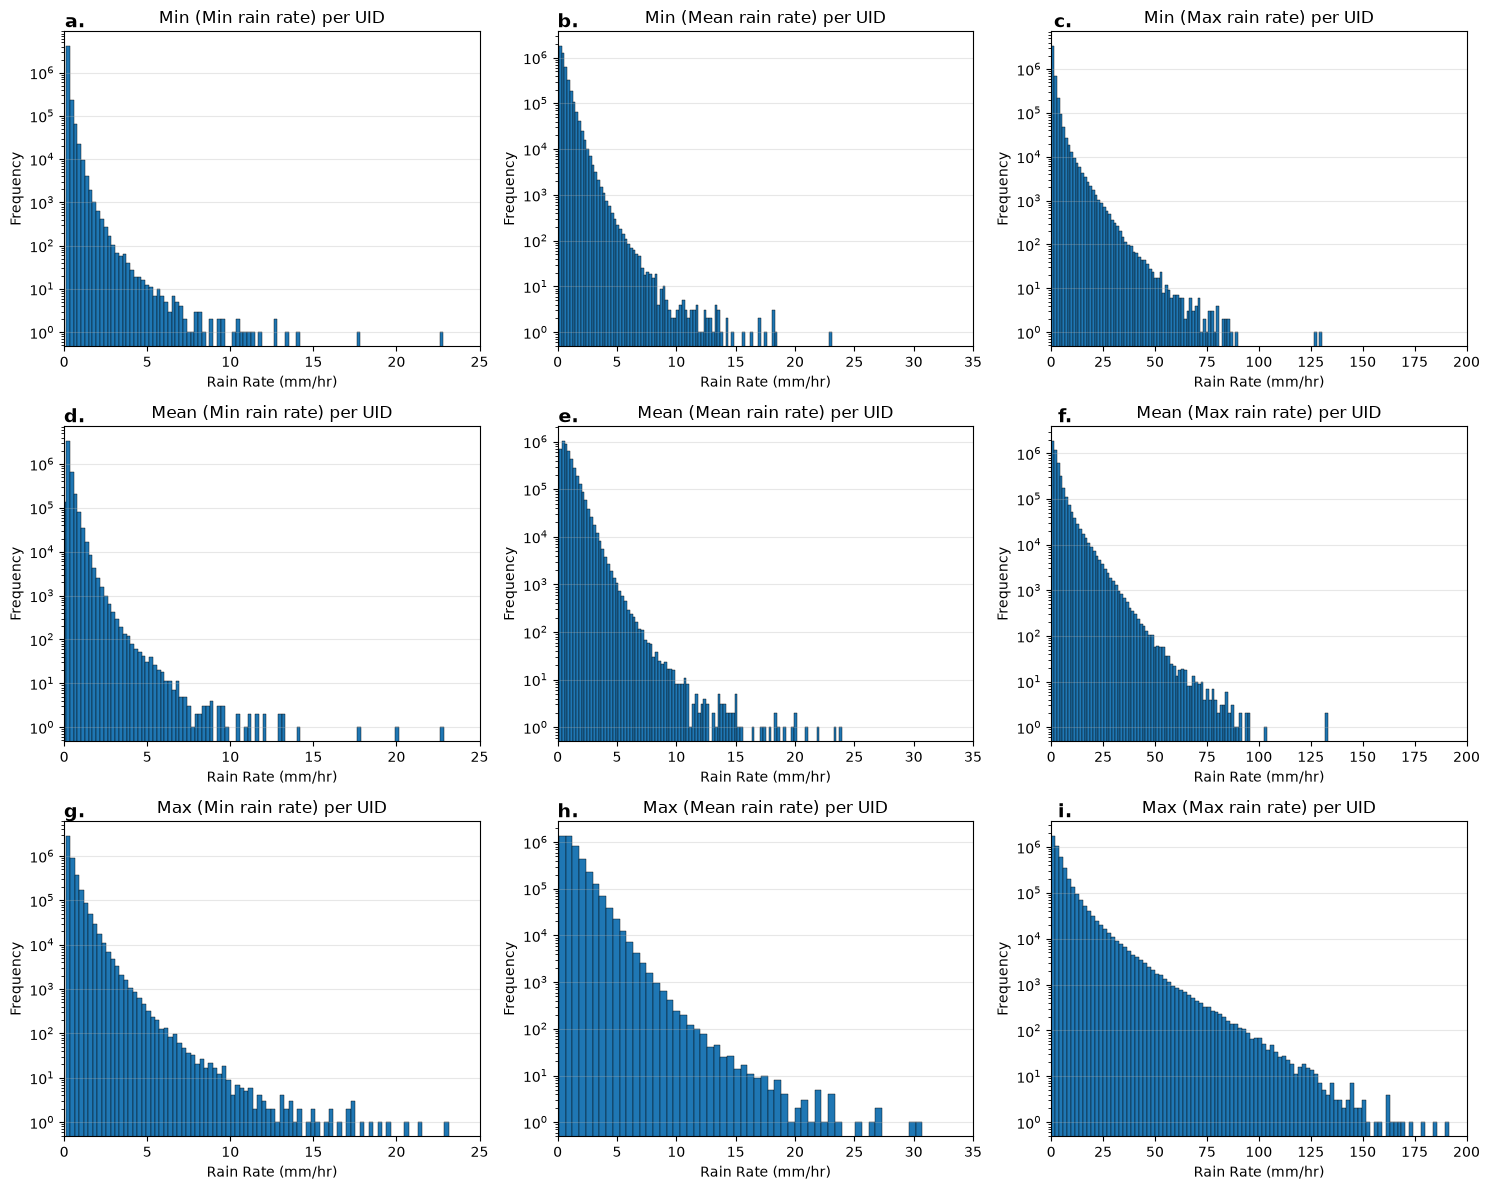

In [5]:
x_limits = {"min": 25, "mean": 35, "max": 200}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
panel = 0
for i, stat in enumerate(statistics):
    for j, var in enumerate(variables):
        ax = axes[i, j]
        column = f"{stat}_{var}"
        hist, bin_width = histograms[column]
        ax.bar(hist["center"], hist["frequency"], width=bin_width, edgecolor="black", linewidth=0.3)
        # ax.set_title(f"{stat.capitalize()} {var}")

        stat_label = stat.capitalize()
        var_label = var.capitalize()
        ax.set_title(f"{stat_label} ({var_label} rain rate) per UID", fontsize=12)

        ax.set_xlim(0, x_limits[var])
        ax.set_xlabel('Rain Rate (mm/hr)')
        ax.set_ylabel("Frequency")
        ax.text(0.05, 1.06, f"{chr(97 + panel)}.", transform=ax.transAxes, fontsize=14, fontweight="bold", ha="right", va="top")
        ax.grid(axis="y", alpha=0.3)
        ax.set_yscale("log")
        panel += 1

plt.tight_layout()
plt.show()